In [1]:
import numpy as np
from scipy.special import jn_zeros
from scipy.optimize import root_scalar, brentq
import matplotlib.pyplot as plt
import scipy.special as sp
from scipy.special import jv, jn_zeros
from scipy.integrate import quad
from joblib import Parallel, delayed

# Solución de la ecuación de difusión del modelo de dos regiones (_Two-Region Model_)

In [2]:
# Parámetros físicos
D1 = 2e4              # nm²/s (región superficial)
D2 = 2e6              # nm²/s (región volumétrica)
z_c = 50              # nm (altura de la interfaz)
L = 1500              # nm (altura total)
R = 1500              # nm (radio del cilindro)
kappa = 150             # nm/s coeficiente de absorción superficial
n_modes_radial = 25   # Número de modos radiales
m_max = 25            # Número de modos axiales por modo radial
N_z = N_r = 15000     # Número de nodos en z y rho

In [3]:
##############################################################################
# 1. Solución Radial R(ρ)
##############################################################################

def D_eff_tworegion(D1, D2, z_c, L):
    L1, L2 = z_c, L - z_c
    return (L1 + L2) / (L1/D1 + L2/D2)

D_eff=D_eff_tworegion(D1, D2, z_c, L)

# Solución de la ecuación trascendental

def robin_eq(alpha):
    return alpha * sp.jv(1, alpha * R) - (kappa / D_eff) * sp.jv(0, alpha * R)

In [4]:
D_eff

465116.27906976745

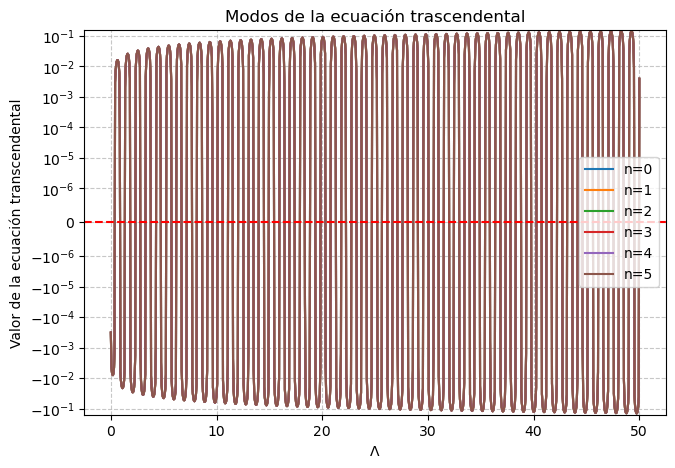

In [5]:
plt.figure(figsize=(7.5,5))
for n in range(min(6,n_modes_radial)):
    alpha_plot=np.linspace(0,50,1000)
    plt.plot(alpha_plot,robin_eq(alpha_plot),label=f'n={n}')
plt.legend()
plt.title("Modos de la ecuación trascendental")
plt.ylabel("Valor de la ecuación transcendental")
plt.xlabel(r"$\Lambda$")
plt.axhline(0, color='red', linestyle='--')
plt.yscale('symlog', linthresh=1e-6)
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/transcendental_radial_tworegion.pdf', bbox_inches='tight')
plt.show()

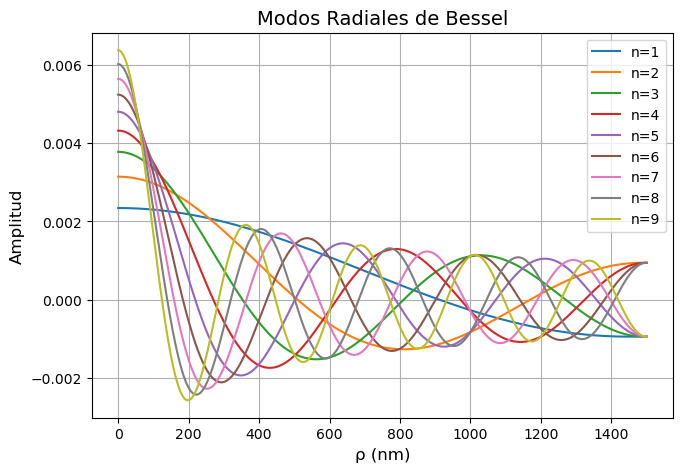

In [6]:
# Estimar raíces con brentq en intervalos [a, b] con cambio de signo
alpha_min = 1e-3
alpha_roots = []
step = 0.001  # Paso inicial para buscar raíces

alpha_current = alpha_min
while len(alpha_roots) < n_modes_radial and alpha_current < 1e5:
    # Buscar raíces en el intervalo [Lambda_current, Lambda_current + step]
    try:
        root = brentq(robin_eq, alpha_current, alpha_current + step, xtol=1e-6)
        alpha_roots.append(root)
        alpha_current = root + step  # Mover el inicio para la próxima búsqueda
    except ValueError:
        alpha_current += step
alpha_n=np.array(alpha_roots)

def R_func(alpha, rho):
    """
    Calcula R_n(rho) = J0(alpha_n * rho) normalizados con la norma analítica
      ∫₀ᴿ J₀²(αₙ ρ) ρ dρ = (R²/2)[J₀²(αₙR) + J₁²(αₙR)].

    Args:
        alpha_n: array de raíces αₙ, shape (n_modes,)
        rho_vals: escalar o array de posiciones radiales, shape (m,)

    Returns:
        R_normed: array (n_modes, m) de los modos normalizados
        norms:    array (n_modes,) con el valor exacto de la norma
    """
   # 1) Aseguramos que alpha_n y rho_vals sean arrays 1D
    alpha_arr = np.atleast_1d(alpha)              # shape (n_modes,)
    rho_arr   = np.atleast_1d(rho)             # shape (m,)

    # 2) Creamos vistas 2D para broadcasting
    alpha = alpha_arr.reshape(-1, 1)                # (n_modes, 1)
    rho   = rho_arr.reshape(1, -1)                  # (1, m)

    # 3) Evaluamos el modo sin normalizar
    R_matrix = sp.jv(0, alpha * rho)                   # (n_modes, m)

    # 4) Calculamos la norma analítica usando alpha_arr (no el escalar viejo)
    J0R = sp.jv(0, alpha_arr * R)                      # (n_modes,)
    J1R = sp.jv(1, alpha_arr * R)                    # (n_modes,)
    norms = 0.5 * R**2 * (J0R**2 + J1R**2)           # (n_modes,)

    # 5) Aseguramos que norms sea un array 1D
    norms = np.atleast_1d(norms)

    # 6) Factor de normalización
    N = 1.0 / np.sqrt(norms)                        # (n_modes,)

    # 7) Aplicamos normalización por filas
    R_normed = N[:, None] * R_matrix                # (n_modes, m)

    return R_normed, np.sqrt(norms)

rho_vals = np.linspace(0.0, R,N_r)
R_values,R_norms=R_func(alpha_n,rho_vals)

# Graficar modos radiales
plt.figure(figsize=(7.5, 5))
for n in range(min(9, n_modes_radial)):
    plt.plot(rho_vals, R_values[n], label=f"n={n+1}", linewidth=1.5)

plt.xlabel("ρ (nm)", fontsize=12)
plt.ylabel("Amplitud", fontsize=12)
plt.title("Modos Radiales de Bessel", fontsize=14)
plt.legend()
plt.grid(True)
plt.savefig("figuras/modos_radiales_tworegion.pdf", bbox_inches="tight")
plt.show()
plt.close()

In [7]:
##############################################################################
# 2. Ecuación trascendental
##############################################################################
def transcendental_eq(Lambda, alpha_n):
    beta_1_sq = (Lambda**2 - alpha_n**2 * D1) / D1
    beta_2_sq = (Lambda**2 - alpha_n**2 * D2) / D2
    
    # if beta_1_sq < 0 or beta_2_sq < 0:
    #     return np.inf  # Evitar raíces complejas
    
    beta_1 = np.sqrt(beta_1_sq)
    beta_2 = np.sqrt(beta_2_sq)
    
    # return (D1 * beta_1*np.cos(beta_2*(L-z_c))-kappa*D2*beta_2/D1/beta_1*np.sin(beta_2*(L-z_c))) * np.sin(beta_1 * z_c) + (kappa**beta_1*np.cos(beta_2*(L-z_c))+D2 * beta_2*np.sin(beta_2 * (L - z_c))) * np.cos(beta_1 * z_c)
    return (kappa*(np.cos(beta_2*(L-z_c))+kappa*np.sin((beta_2*(L-z_c))))-D2*beta_2*(np.sin(beta_2*(L-z_c))-kappa*np.cos(beta_2*(L-z_c))))*np.cos(beta_1*z_c)-(D1*beta_1*(np.cos(beta_2*(L-z_c))+kappa*np.sin(beta_2*(L-z_c)))+kappa*beta_2*D2/D1/beta_1*(np.sin(beta_2*(L-z_c))-kappa*np.cos(beta_2*(L-z_c))))*np.sin(beta_1*z_c)

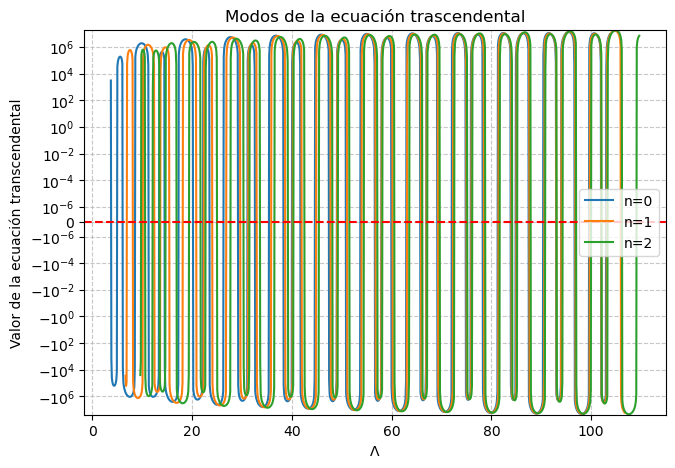

In [8]:
plt.figure(figsize=(7.5,5))
for n in range(3):
    Lambda=np.linspace(alpha_n[n]*np.sqrt(D2)+1e-3,1e2+alpha_n[n]*np.sqrt(D2)+1e-3,1000)
    plt.plot(Lambda,transcendental_eq(Lambda,alpha_n[n]),label=f'n={n}')
plt.legend()
plt.title("Modos de la ecuación trascendental")
plt.ylabel("Valor de la ecuación transcendental")
plt.xlabel(r"$\Lambda$")
plt.axhline(0, color='red', linestyle='--')
plt.yscale('symlog', linthresh=1e-6)
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/transcendental_axial_tworegion.pdf', bbox_inches='tight')
plt.show()

In [9]:
##############################################################################
# 3. Búsqueda de autovalores Λ para un α_n dado
##############################################################################

def find_m_roots(alpha, Lambda_max=1e5):
    Lambda_min = alpha * np.sqrt(D2)+1e-3
    roots = []
    step = 0.1  # Paso inicial para buscar raíces
    
    Lambda_current = Lambda_min
    while len(roots) < m_max and Lambda_current < Lambda_max:
        # Buscar raíces en el intervalo [Lambda_current, Lambda_current + step]
        try:
            root = brentq(transcendental_eq, Lambda_current, Lambda_current + step,
                           args=(alpha), xtol=1e-6)
            roots.append(root)
            Lambda_current = root + step  # Mover el inicio para la próxima búsqueda
        except ValueError:
            Lambda_current += step
    
    return roots[:m_max]  # Devuelve hasta m_max raíces

axial_results = Parallel(n_jobs=4, verbose=1)(delayed(find_m_roots)(alpha) for n, alpha in enumerate(alpha_n))
# Encontrar raíces para cada αₙ hasta m_max
eigenvalues_ax = {}
for n,alpha in enumerate(alpha_n):
    eigenvalues_ax[n] = axial_results[n]

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  25 out of  25 | elapsed:    1.4s finished


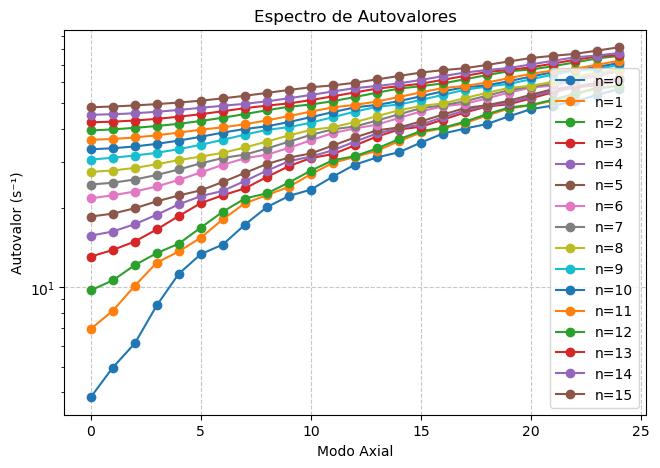

In [10]:
# Graficar espectro de autovalores
plt.figure(figsize=(7.5,5))
for n in range(min(16,n_modes_radial)):
    evals = eigenvalues_ax[n]
    plt.semilogy(evals, 'o-', label=f'n={n}')
plt.xlabel('Modo Axial')
plt.ylabel('Autovalor (s⁻¹)')
plt.title('Espectro de Autovalores')
plt.legend()
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/eigenvalues_tworegion.pdf', bbox_inches='tight')
plt.show()
plt.close()

## Cálculo de la constante $B$ de las funciones $Z_1(z)$ y $Z_2(z)$

Las funciones $Z_1(z)$ y $Z_2(z)$ se encuentran multiplicadas por una constante $B$.

$$Z_1(z)=B\left[\cos{(\beta_1z)}-\frac{\kappa}{D_1\beta_1}\sin{(\beta_1z)}\right]$$

$$Z_2(z)=B\left[\cos{(\beta_1z_c)}-\frac{\kappa}{D_1\beta_1}\sin{(\beta_1z_c)}\right]\left\{\tan{\left[\beta_2\left(L-z_c\right)\right]}\sin{\left[\beta_2\left(z-z_c\right)\right]}+\cos{\left[\beta_2\left(z-z_c\right)\right]}\right\}$$

Se debe cumplir que

$$\int_0^LZ^2(z)dz=1$$

Por lo que es posible separar la integral en los dos dominios de integración:

$$\int_0^{z_c}Z_1^2(z)dz+\int_{z_c}^LZ_2^2(z)dz=1$$

Se llama como $f_{1}(z)=\frac{Z_1(z)}{B}=\cos{(\beta_1z)}-\frac{\kappa}{D_1\beta_1}\sin{(\beta_1z)}$ y $f_{2}(z)=\frac{Z_2(z)}{B}=\left[\cos{(\beta_1z_c)}-\frac{\kappa}{D_1\beta_1}\sin{(\beta_1z_c)}\right]\left\{\tan{\left[\beta_2\left(L-z_c\right)\right]}\sin{\left[\beta_2\left(z-z_c\right)\right]}+\cos{\left[\beta_2\left(z-z_c\right)\right]}\right\}$

De forma que la integral queda como:

$$B^2\left(\int_0^{z_c}f_1^2(z)dz+\int_{z_c}^Lf_2^2(z)dz\right)=1$$

Y al despejar $B$:

$$B=\frac{1}{\sqrt{\int_0^{z_c}f_1^2(z)dz+\int_{z_c}^Lf_2^2(z)dz}}$$


De forma que $B$ depende de los modos radiales y axiales; sin embargo, se puede integrar el cálclo de los coeficientes $A_n$, $B_{n,m}$ y $T_{n,m}$ en una sola solución

In [11]:
##############################################################################
# 4. Z(z) sin coeficientes
##############################################################################
z=np.linspace(0,L,N_z)

# Definir fz_raw vectorizado
def fz_raw(z_val, n, m):
    z = np.array(z_val, dtype=float)
    # modos
    r_mode = alpha_n[n]
    z_mode = eigenvalues_ax[n][m]
    
    beta_1 = np.sqrt((z_mode**2 - r_mode**2 * D1) / D1)
    beta_2 = np.sqrt((z_mode**2 - r_mode**2 * D2) / D2)
    
    # expresiones para cada región
    expr1 = np.cos(beta_1 * z) - (kappa / (D1 * beta_1)) * np.sin(beta_1 * z)
    expr2 = (np.cos(beta_1 * z_c) - (kappa / (D1 * beta_1)) * np.sin(beta_1 * z_c)) * \
            (np.tan(beta_2 * (L - z_c)) * np.sin(beta_2 * (z - z_c)) + np.cos(beta_2 * (z - z_c)))
    
    # seleccionar por región
    return np.where(z <= z_c, expr1, expr2)
    
z = np.linspace(0, L, N_z)

# Cálculo de C_nm vectorizado
C_nm = np.zeros((n_modes_radial, m_max))
for n in range(n_modes_radial):
    for m in range(m_max):
        Z_vals = fz_raw(z, n, m)
        integral = np.trapz(Z_vals**2, z)
        C_nm[n, m] = 1.0 / np.sqrt(integral)

# Función normalizada
def fz(z_val, n, m):
    return C_nm[n, m] * fz_raw(z_val, n, m)

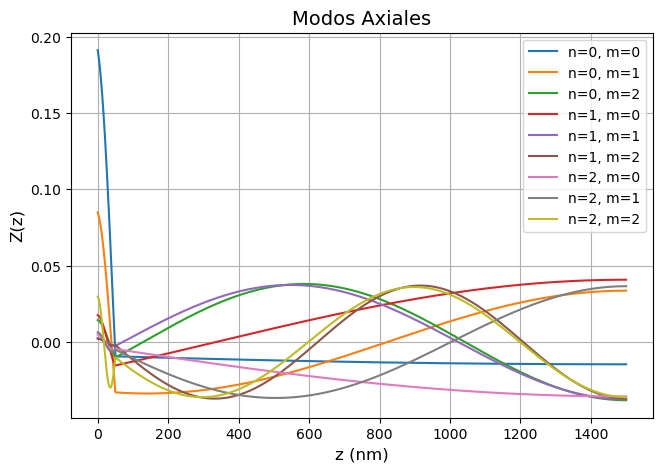

In [12]:
plt.figure(figsize=(7.5,5))
for n in range(3):
    for m in range(3):
        Zs=[]
        for z_val in z:
            Zs.append(fz(z_val,n,m))
        plt.plot(z,np.array(Zs), label=f"n={n}, m={m}", linewidth=1.5)
plt.xlabel("z (nm)", fontsize=12)
plt.ylabel("Z(z)", fontsize=12)
plt.title("Modos Axiales", fontsize=14)
plt.legend()
plt.grid(True)
plt.savefig("figuras/modos_axiales_tworegion.pdf", bbox_inches="tight")
plt.show()
plt.close()    

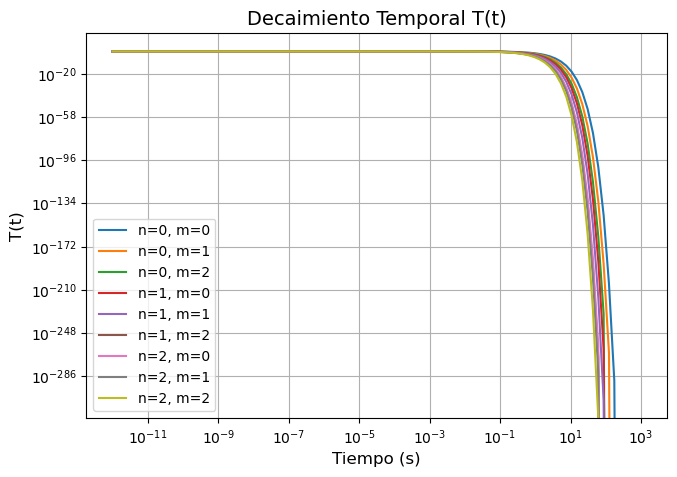

In [13]:
##############################################################################
# 5. Término Temporal T(t)
##############################################################################
# Ahora, para cada eigenvalor (de la parte axial) usaremos el valor absoluto
# para que T(t)=exp(-|λ| t) decaiga.
def T(t, lam):
    return np.exp(-np.abs(lam) * t)

# Graficamos T(t) para los modos del sistema axial
plt.figure(figsize=(7.5,5))
t_plot = np.logspace(-12, 3, 100)
for n in range(min(3,n_modes_radial)):
    for m in range(min(3, m_max)):
        lam = eigenvalues_ax[n][m]
        plt.loglog(t_plot, T(t_plot, lam), label=f"n={n}, m={m}", linewidth=1.5)
plt.xlabel("Tiempo (s)", fontsize=12)
plt.ylabel("T(t)", fontsize=12)
plt.title("Decaimiento Temporal T(t)", fontsize=14)
plt.legend()
plt.grid(True, which="both")
plt.savefig("figuras/T_t_tworegion.pdf", bbox_inches="tight")
plt.show()
plt.close()

In [14]:
##############################################################################
# 6. Cálculo de Coeficientes A_{nm}
##############################################################################
# Se asume que la condición inicial es:
#     P(ρ, z, 0) ∝ δ(ρ-ρ0) δ(z-z0) / (2πρ0)
# Con ρ0 = 750 nm y z0 = 10 nm.
rho0 = 750  # nm
z0 = 10    # nm

def compute_A_nm(n):
    """Calcula A_{n,m} para un modo radial fijo n."""
    A_nm = np.zeros(m_max)
    alpha = alpha_n[n]
    
    for m in range(m_max):
               
        # 1. Evaluar Z_{n,m}(z0)
        Z_z0 = fz(z0,n,m)
        
        # 2. Evaluar R_n(ρ0)
        R_rho0 = R_func(alpha,rho0)[0].flatten()
        
        # 3. Calcular A_{n,m}
        A_nm[m] = (R_rho0 * Z_z0) / (2 * np.pi)
    
    return A_nm

# Cálculo paralelizado
A_nm = Parallel(n_jobs=4)(delayed(compute_A_nm)(n) for n in range(n_modes_radial))

In [15]:
eig_arr = np.array([
    [eigenvalues_ax[n][m] for m in range(m_max)]
    for n in range(n_modes_radial)
])

# Si A_nm no es aún array, conviértelo también:
A_arr = np.array(A_nm)  # asumiendo que A_nm es lista de listas

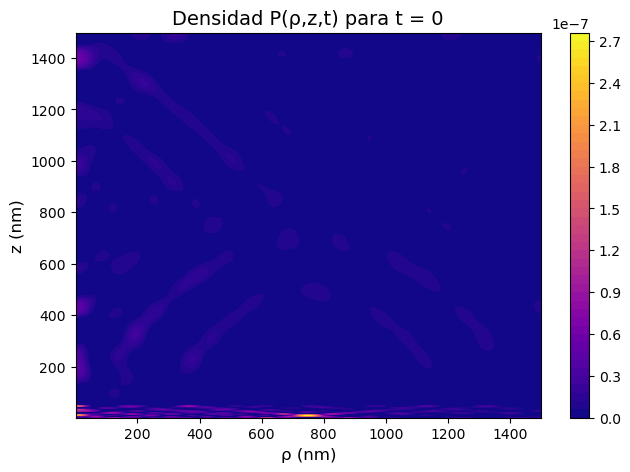

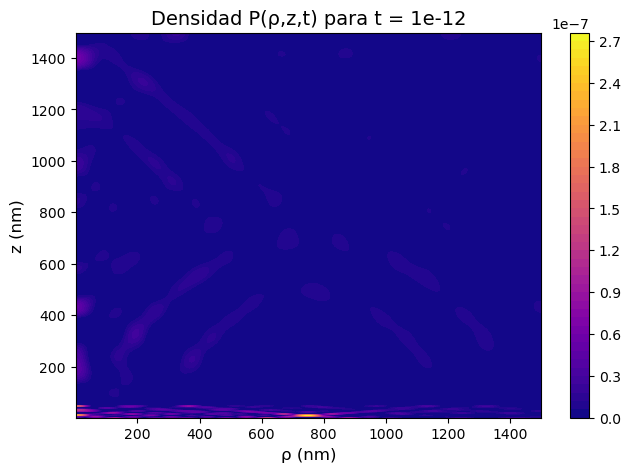

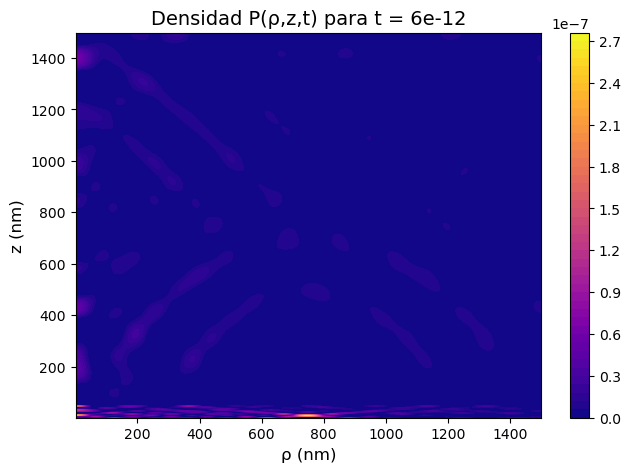

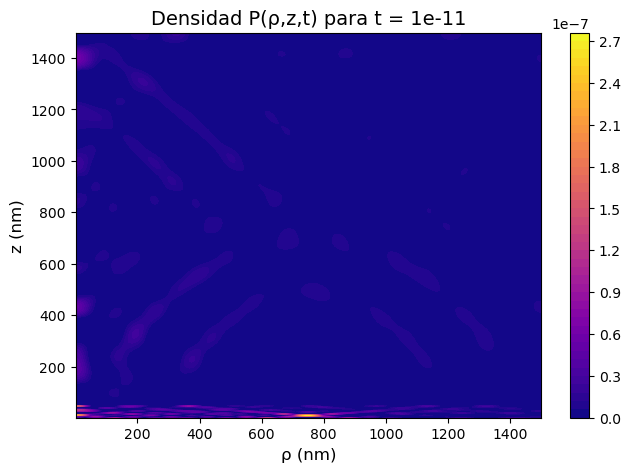

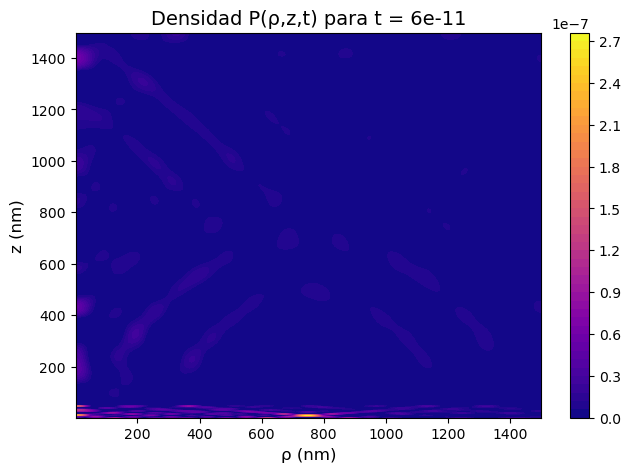

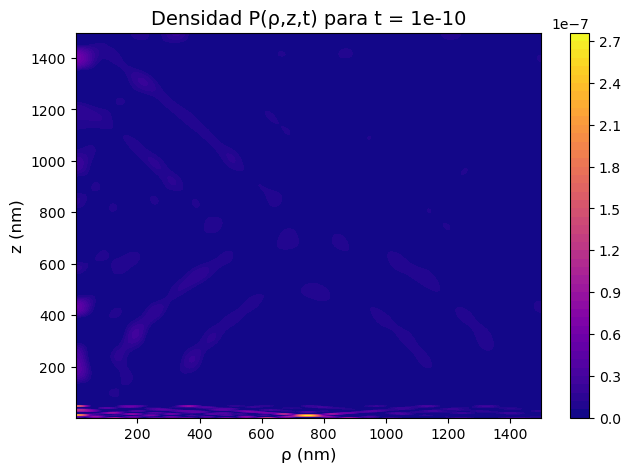

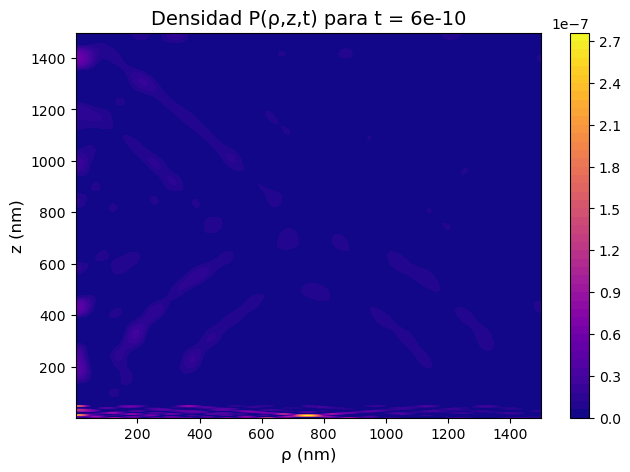

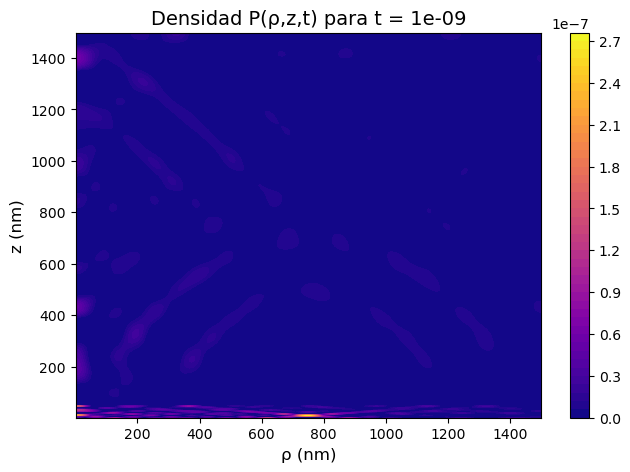

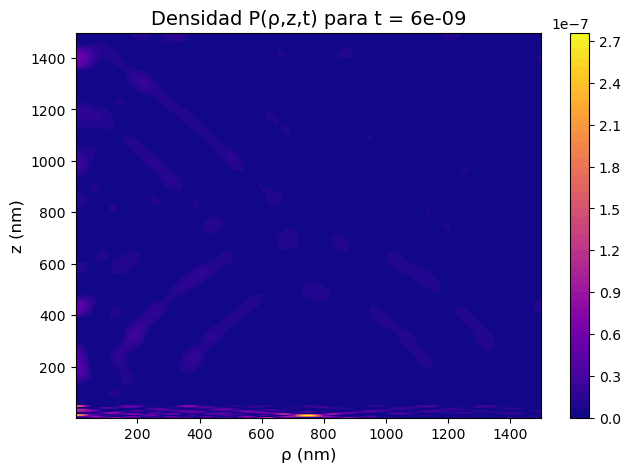

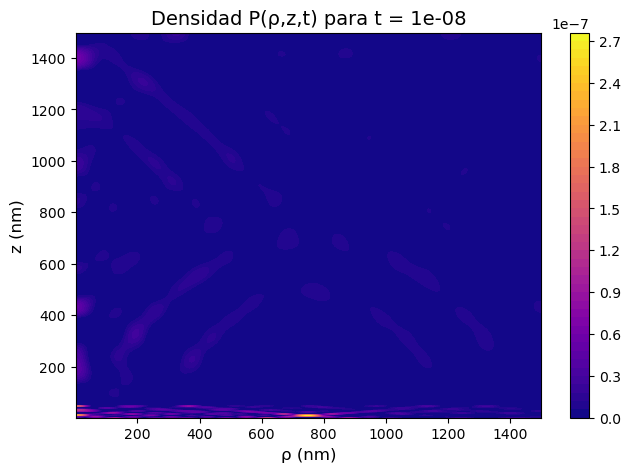

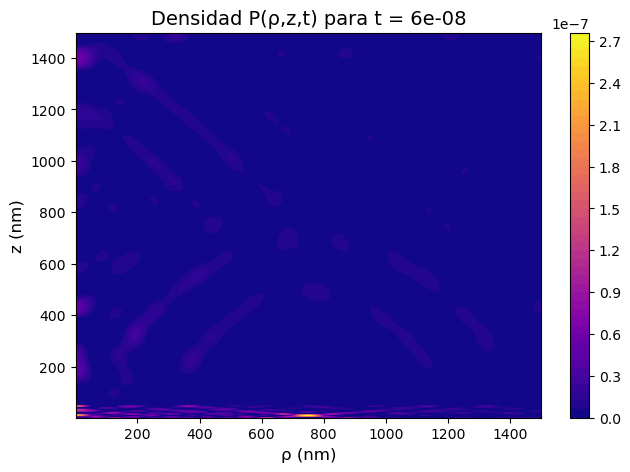

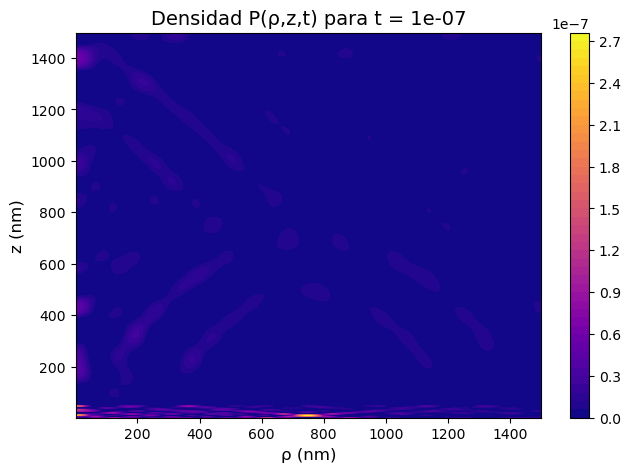

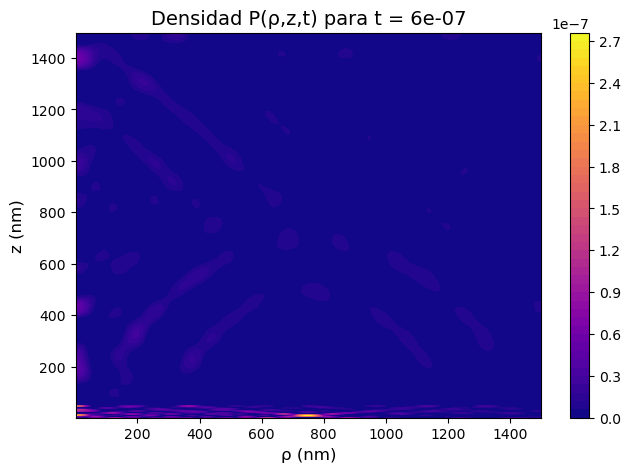

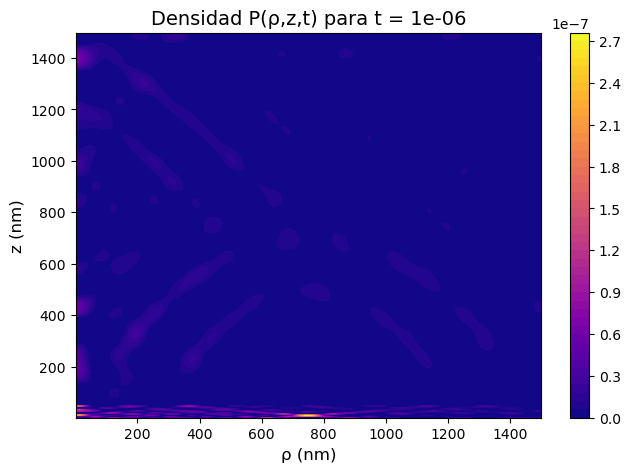

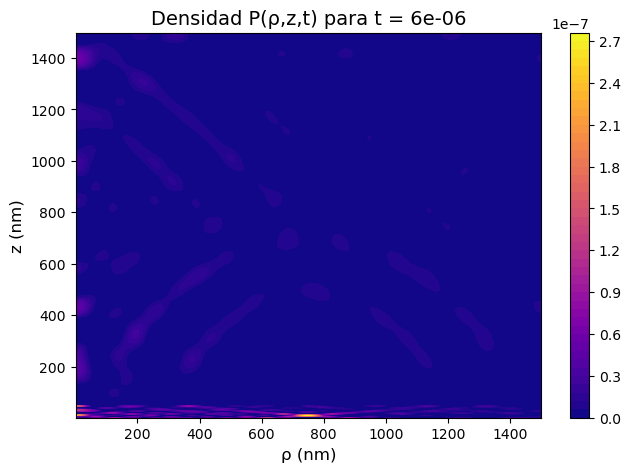

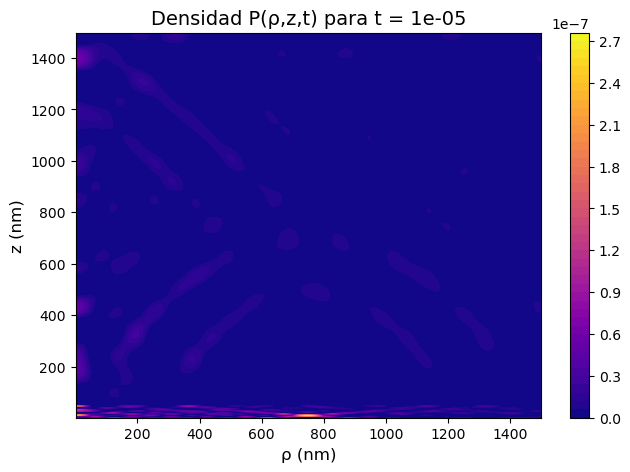

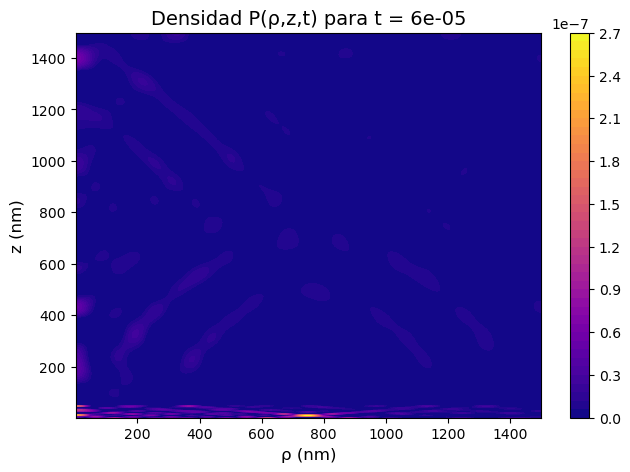

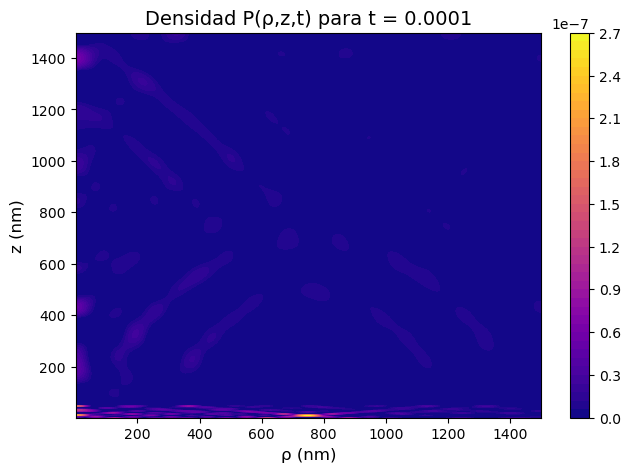

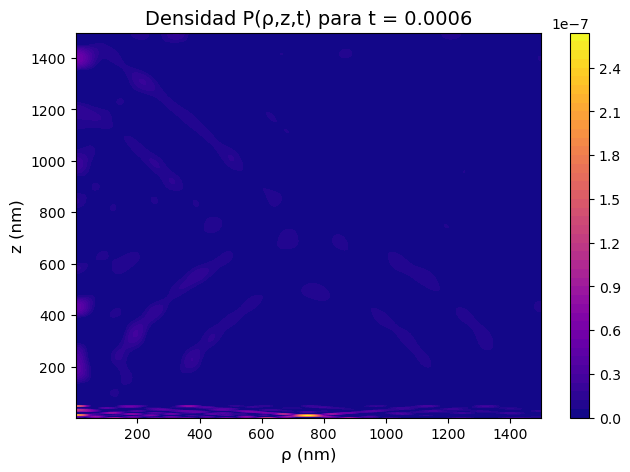

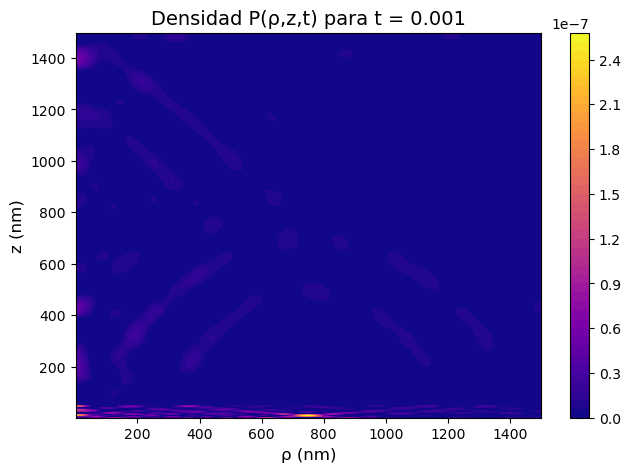

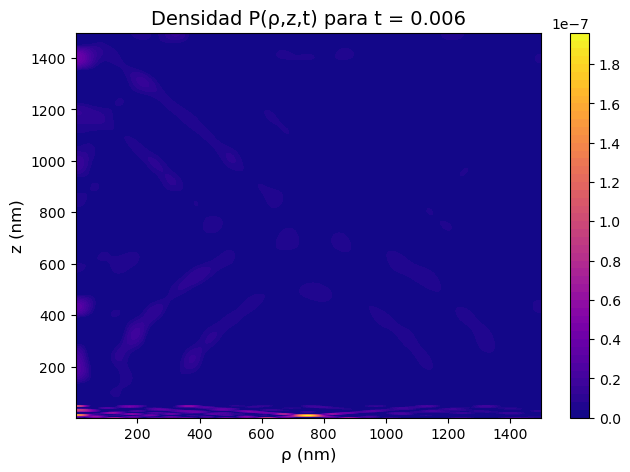

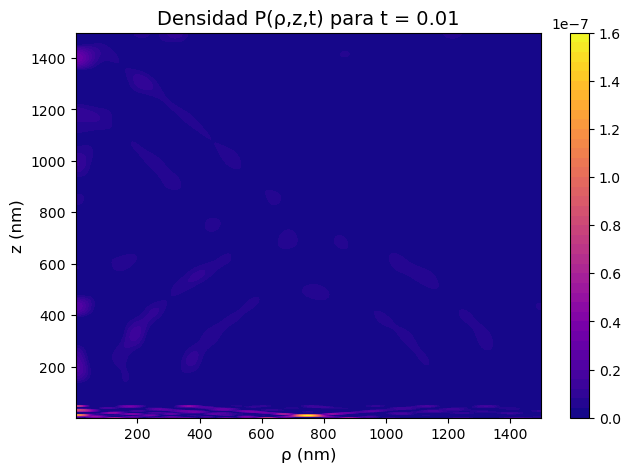

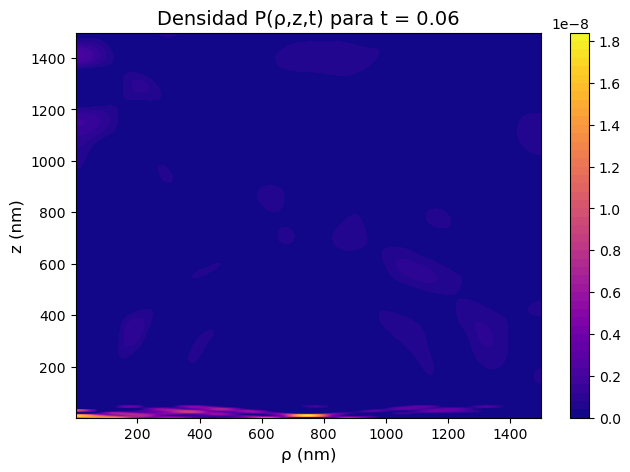

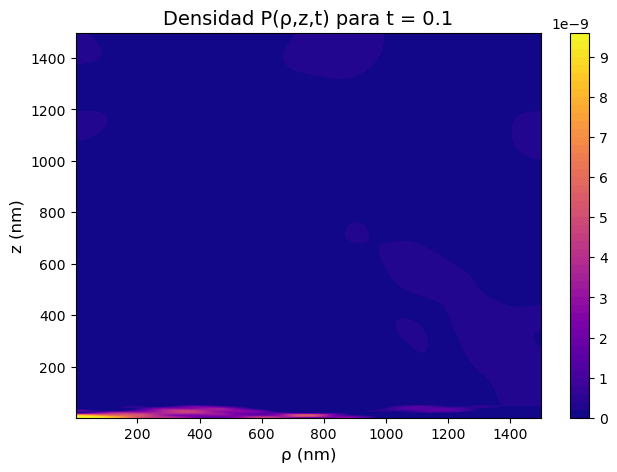

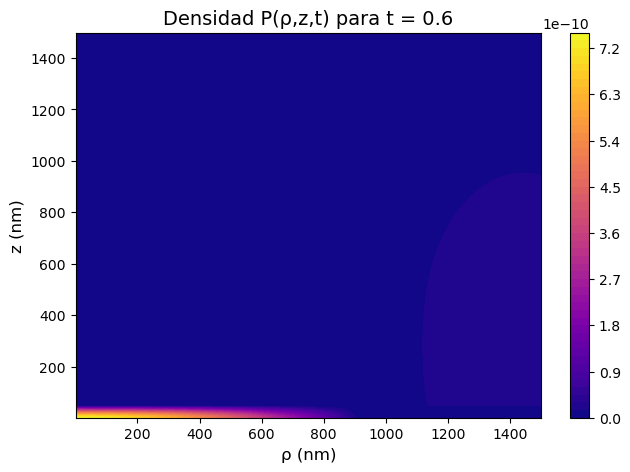

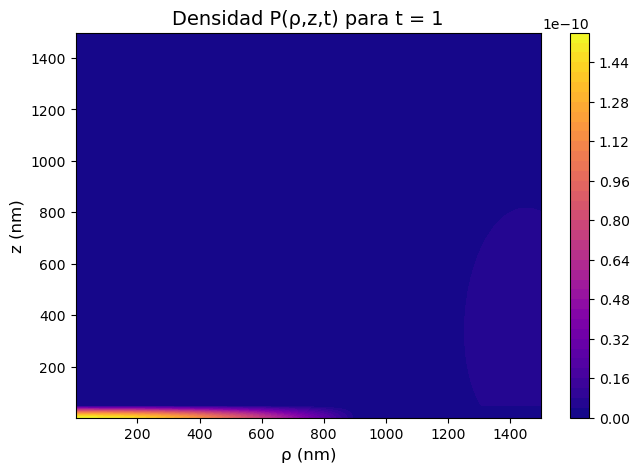

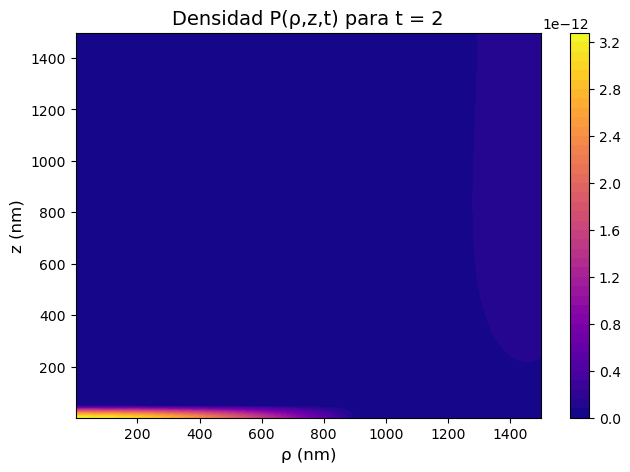

In [16]:
##############################################################################
## # 7. Densidad de Probabilidad P(ρ,z,t)
##############################################################################

def compute_P_vec(rho_vals, z_vals, t):
    """
    Vectorized computation of P(rho, z, t).
    
    Parameters:
    - rho_vals: 1D array of radial positions (Nr,)
    - z_vals:   1D array of axial positions  (Nz,)
    - t:        scalar time

    Returns:
    - P: 2D array of shape (Nz, Nr)
    """
    # Precompute Bessel J0 for all radial modes and rho
    # J0_mat shape: (n_modes, Nr)
    R0_mat,_ = R_func(alpha_n, rho_vals)
    
    # Precompute axial modes Z_tens: shape (Nz, n_modes, m_max)
    Nz = len(z_vals)
    n_modes, m_max = eig_arr.shape
    Z_tens = np.zeros((Nz, n_modes, m_max))
    for n in range(n_modes):
        for m in range(m_max):
            Z_tens[:, n, m] = fz(z_vals, n, m)
    
    # Temporal decay T: shape (n_modes, m_max)
    T_decay = np.exp(-np.abs(eig_arr) * t)
    # Combine coefficients with normalization and decay: shape (n_modes, m_max)
    W = A_arr * T_decay
    
    # Sum over axial modes m → B shape (Nz, n_modes)
    B = np.sum(Z_tens * W[None, :, :], axis=2)
    
    # Combine with radial modes → S shape (Nr, Nz)
    # J0_mat.T: (Nr, n_modes), B.T: (n_modes, Nz)
    S = np.dot(R0_mat.T, B.T)
    
    # Return absolute value, shaped back to (Nz, Nr)
    return np.maximum(S.T, 0)

rho_vals = np.linspace(0.001 * R, 0.999 * R, 1000)
z_vals = np.linspace(0.001*L, 0.999*L, 1000)
for t_val in [0,1e-12,6e-12,1e-11,6e-11,1e-10,6e-10,1e-9,6e-9,1e-8,6e-8,1e-7,6e-7,1e-6,6e-6,1e-5,6e-5,1e-4,6e-4,1e-3,6e-3,1e-2,6e-2,1e-1,6e-1,1,2]:
    P_val = compute_P_vec(rho_vals, z_vals, t=t_val)
    
    plt.figure(figsize=(7.5,5))
    plt.contourf(rho_vals, z_vals, P_val, 50, cmap="plasma")
    plt.xlabel("ρ (nm)", fontsize=12)
    plt.ylabel("z (nm)", fontsize=12)
    plt.title(f"Densidad P(ρ,z,t) para t = {t_val}", fontsize=14)
    plt.colorbar()
    plt.savefig(f"figuras/P_contour_tworegion_{t_val}.pdf", bbox_inches="tight")
    plt.show()
    plt.close()

In [17]:
s = 0.0
for n in range(n_modes_radial):
    for m in range(m_max):
        s += (
            A_nm[n][m]
            * R_func(alpha_n[n],rho0)[0][0,0] / R_norms[n]
            * fz(z0,n,m)
        )
print("s =", s, " vs 1/(2πρ0) =", 1/(2*np.pi*rho0))

s = 1.9378066503965398e-09  vs 1/(2πρ0) = 0.0002122065907891938


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  76 tasks      | elapsed:    2.7s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:    3.4s finished


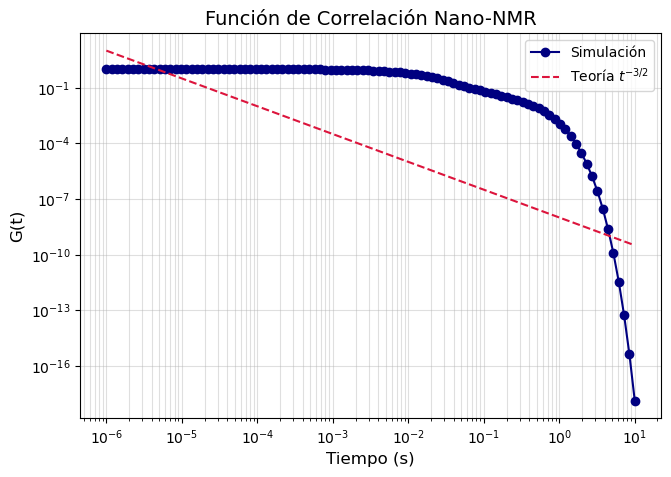

In [20]:
##############################################################################
# 8. Función de Correlación G(t)
##############################################################################

def compute_G_vec(t, N_quad=100):
    # 1. Mallado
    rho = np.linspace(0.3*R, 0.7*R, N_quad)              # (Nr,)
    z   = np.linspace(5, 55, N_quad)              # (Nz,)
    dr  = (0.7*R - 0.3*R)/N_quad

    # 2. Precompute J0 for todos los modos radiales y todos los rho
    #    J0_mat[n, i] = J0(alpha_n[n] * rho[i])
    R0_mat,_ = R_func(alpha_n,rho)       # (n_modes, Nr)

    # 3. Precompute Z para todos los modos (n,m) y todos los z
    #    Z_tens[j, n, m] = fz(z[j], n, m)
    Z_tens = np.zeros((N_quad, n_modes_radial, m_max))
    for n in range(n_modes_radial):
        for m in range(m_max):
            Z_tens[:, n, m] = fz(z, n, m)                   # vectorizado en z

    # 4. Calcular decaimiento temporal y coeficientes combinados
    #    W[n,m] = A_nm[n,m] * exp(-|λ[n,m]| * t)
    T = np.exp(-np.abs(eig_arr) * t)                # (n_modes, m_max)
    W = A_arr * T                                           # (n_modes, m_max)

    # 5. Colapsar la suma en m: B[j,n] = sum_m Z_tens[j,n,m] * W[n,m]
    #    tensordot sobre el eje m (2) de Z_tens y eje 1 de W
    # B = np.tensordot(Z_tens, W, axes=([2], [1]))            # (Nz, n_modes)
    B = np.sum(Z_tens * W[None, :, :], axis=2)         # → (Nz, n_modes_radial)
    # 6. Colapsar la suma en n: S[i,j] = sum_n J0_mat[n,i] * B[j,n]
    #    equivalente a multiplicación de matrices
    #    J0_mat.T: (Nr, n_modes),  B.T: (n_modes, Nz)
    S = np.dot(R0_mat.T, B.T)                              # (Nr, Nz)

    # 7. Factor dipolar y suma final
    #    f_mat[i,j] = (3*z[j]^2 - rho[i]^2) / (rho[i]^2 + z[j]^2)^2.5
    R2 = rho**2;  Z2 = z**2
    # Broadcasting para construir la matriz (Nr, Nz)
    f_mat = (3*Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :] )**2.5

    total = np.sum(np.abs(rho[:, None] * f_mat * S))

    # 8. Prefactor y retorno
    return (5/(16*np.pi)) * (total * dr)

t_values = np.logspace(-6, 1, 100)
G_values = Parallel(n_jobs=4, verbose=1)(delayed(compute_G_vec)(t) for t in t_values)

np.savetxt("data/G_vs_t_tworegion.dat", np.c_[t_values, G_values], header="Tiempo(s) G(t)", fmt="%.8e")

plt.figure(figsize=(7.5,5))
plt.loglog(t_values, G_values/G_values[0], "o-", label="Simulación", color="navy", markersize=6, linewidth=1.5)
plt.plot(t_values, 1e-8 * t_values**-1.5, "--", label=r"Teoría $t^{-3/2}$", color="crimson", linewidth=1.5)
plt.xlabel("Tiempo (s)", fontsize=12)
plt.ylabel("G(t)", fontsize=12)
plt.title("Función de Correlación Nano-NMR", fontsize=14)
plt.legend()
plt.grid(which="both", alpha=0.4)
plt.savefig("figuras/correlacion_nanoNMR_tworegion.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()